# RL 21 - Auto-jeu à la AlphaZero : quand le réseau guide l'arbre de recherche

> **Position dans la série.** Ce notebook exécute, sur un jeu à information parfaite de taille
> maîtrisée, la boucle centrale d'*AlphaZero* (Silver et al. 2017, *Mastering Chess and Shogi by
> Self-Play with a General Reinforcement Learning Algorithm*, arXiv:1712.01815) : un MCTS guidé par
> un réseau de neurones joue contre lui-même, la distribution de visites de la recherche devient la
> cible d'entraînement de la politique du réseau, et le réseau amélioré guide la recherche suivante.
> Aucune donnée humaine, aucune table d'ouverture : la qualité jaillit du couplage
> recherche-apprentissage. Le papier raisonne à l'échelle des supercalculateurs ; nous le réduisons
> à une taille exécutable sur CPU en quelques minutes, sans en trahir la mécanique.

**Navigation** : [README série](README.md) — précédent : [RL-19-Reward-Tampering](RL-19-Reward-Tampering-Python.ipynb) — cousin de recherche : [Search-07-MCTS-And-Beyond](../Search/Part1-Foundations/Search-07-MCTS-And-Beyond.ipynb)


## 0. Ce que ce carnet change : la recherche devient l'opérateur d'amélioration

Les carnets précédents de la série améliorent une politique par **gradient direct** sur des
trajectoires collectées au hasard des interactions (DQN, PPO, GRPO...). Ici la structure s'inverse :

1. un **MCTS** exécuté depuis l'état courant produit une distribution de visites $\pi(a \mid s)$ —
   une politique *meilleure* que celle du réseau, parce qu'elle corrige ses erreurs par la recherche ;
2. le réseau est entraîné à **imiter cette politique améliorée** et à prédire l'issue $z$ de la
   partie — une itération de politique dont l'opérateur d'amélioration est la recherche ;
3. le réseau amélioré **guide la recherche suivante** par ses priors et son évaluation de valeur.

La série [Search](../Search/Part1-Foundations/Search-07-MCTS-And-Beyond.ipynb) exécute déjà le MCTS
classique (UCB1, rollouts aléatoires) comme **algorithme de recherche** : quatre phases — sélection,
expansion, simulation, rétropropagation. Nous réutilisons exactement cette terminologie et ce
squelette, avec deux modifications signature AlphaZero :

| | MCTS classique (Search-07) | MCTS guidé réseau (ce carnet) |
|---|---|---|
| Sélection | UCB1 : $Q + c\sqrt{\ln N / n}$ | PUCT : $Q + c_{puct} \cdot P(a\mid s) \cdot \frac{\sqrt{N}}{1 + n}$ |
| Évaluation d'une feuille | **rollout aléatoire** jusqu'à la fin de partie | **valeur du réseau** $v_\theta(s)$ (pas de rollout) |
| Politique a priori | uniforme | sortie de la tête politique du réseau |

La question expérimentale du carnet — à garder en tête tout du long — est donc : **à budget de
simulations égal, que vaut la guidance du réseau ?** Nous y répondrons par un tournoi contrôlé
(section 6) : MCTS+réseau contre MCTS classique à budget identique.


In [1]:
import math
import random
import time

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)  # plus rapide (et deterministe) pour un petit modele sur CPU
DEVICE = torch.device("cpu")
print("torch", torch.__version__, "| device:", DEVICE, "| threads:", torch.get_num_threads())

torch 2.14.0+cu126 | device: cpu | threads: 1


In [2]:
BATCH_MODE = False   # papermill -p BATCH_MODE True : reduit les affichages de suivi
SMOKE = False        # papermill -p SMOKE True : budgets reduits pour tester le code rapidement

In [3]:
# Budgets d'execution. Les valeurs SMOKE servent uniquement a verifier que le code tourne ;
# toutes les mesures commitees proviennent des valeurs nominales.
K_ITERATIONS = 1 if SMOKE else 20       # iterations auto-jeu -> entrainement
PARTIES_AUTOJEU = 2 if SMOKE else 14    # parties generees par iteration
SIMULATIONS = 8 if SMOKE else 40        # simulations MCTS par coup
EPOCHS = 1 if SMOKE else 8              # passes d'entrainement par iteration
C_PUCT = 1.5                            # coefficient d'exploration PUCT
DIRICHLET_ALPHA = 0.3                   # concentration du bruit a la racine
DIRICHLET_EPS = 0.25                    # poids du bruit dans les priors racine
MATCHS_TOURNOI = 2 if SMOKE else 8      # matchs par paire et par couleur au tournoi
MATCHS_MULTI_SEED = 4 if SMOKE else 10  # matchs par couleur pour la mesure multi-seed
print("budget:", dict(K=K_ITERATIONS, parties=PARTIES_AUTOJEU, sims=SIMULATIONS, epochs=EPOCHS))

budget: {'K': 20, 'parties': 14, 'sims': 40, 'epochs': 8}


## 1. Le monde : un Puissance 4 réduit (6 colonnes, 5 lignes, alignement 4)

Le choix du jeu est une décision expérimentale, pas une commodité — la taille du jeu détermine
qui, du rollout ou du réseau, a l'avantage :

- le **morpion** est trop petit : résolu par recherche exhaustive, le MCTS pur y est déjà
  quasi optimal — aucune marge pour que la guidance du réseau *discrimine* ;
- une grille trop petite (4×4, 5×4) rend le **rollout aléatoire omniscient** : une partie y dure
  moins de 20 coups, donc chaque rollout atteint la vraie fin de partie — le MCTS classique
  dispose alors d'un oracle gratuit qu'aucune valeur apprise ne peut surpasser ;
- le **Puissance 4 réglementaire** (7×6) coûte trop cher pour un entraînement CPU borné ;
- la grille **6×5 avec alignement de 4** est le point d'équilibre : jusqu'à 30 coups, l'horizon
  des menaces (4 à 8 coups d'avance) dépasse ce qu'un rollout aléatoire évalue de façon fiable —
  c'est précisément là qu'une valeur apprise doit prendre le relais.

C'est l'exigence du dépôt sur les démonstrations de moteurs : le problème doit être assez riche
pour que la capacité annoncée (ici, la guidance réseau) soit **visible dans la sortie**.

In [4]:
COLONNES = 6
LIGNES = 5
ALIGNEMENT = 4
DIRECTIONS = [(0, 1), (1, 0), (1, 1), (1, -1)]  # vertical, horizontal, deux diagonales


class JeuPuissance4:
    """Puissance 4 reduit 6x5, alignement de 4. Grille : numpy (LIGNES, COLONNES),
    ligne 0 = sommet, derniere ligne = sol. Le joueur +1 commence ; -1 est l'adversaire."""

    def __init__(self):
        self.grille = np.zeros((LIGNES, COLONNES), dtype=np.int8)
        self.joueur = 1       # joueur a qui c'est de jouer
        self.coups = 0
        self.vainqueur = 0    # 0 = partie en cours ; +1/-1 = vainqueur ; None = nul (grille pleine)

    def coups_legaux(self):
        return [c for c in range(COLONNES) if self.grille[0, c] == 0]

    def _case_libre(self, colonne):
        for l in range(LIGNES - 1, -1, -1):        # du sol vers le haut
            if self.grille[l, colonne] == 0:
                return l
        return None

    def jouer(self, colonne):
        """Joue le coup pour self.joueur puis bascule le joueur courant. Retourne self."""
        ligne = self._case_libre(colonne)
        if ligne is None:
            raise ValueError(f"colonne {colonne} pleine")
        self.grille[ligne, colonne] = self.joueur
        self.coups += 1
        if self._aligne(ligne, colonne):
            self.vainqueur = self.joueur
        elif self.coups == LIGNES * COLONNES:
            self.vainqueur = None                    # nul : grille pleine
        self.joueur = -self.joueur
        return self

    def _aligne(self, ligne, colonne):
        j = self.grille[ligne, colonne]
        for dl, dc in DIRECTIONS:
            n = 1
            for sens in (1, -1):
                l, c = ligne + sens * dl, colonne + sens * dc
                while 0 <= l < LIGNES and 0 <= c < COLONNES and self.grille[l, c] == j:
                    n += 1
                    l += sens * dl
                    c += sens * dc
            if n >= ALIGNEMENT:
                return True
        return False

    def est_termine(self):
        return self.vainqueur != 0

    def clone(self):
        autre = JeuPuissance4.__new__(JeuPuissance4)
        autre.grille = self.grille.copy()
        autre.joueur = self.joueur
        autre.coups = self.coups
        autre.vainqueur = self.vainqueur
        return autre

    def rendu(self):
        lignes = ["  " + " ".join(str(c) for c in range(COLONNES))]
        for l in range(LIGNES):
            lignes.append(" |" + "|".join({1: "X", -1: "O", 0: "."}[v] for v in self.grille[l]) + "|")
        lignes.append("  " + "-" * (2 * COLONNES - 1))
        return "\n".join(lignes)


# Verification rapide des regles : X empile la colonne 0, O ne bloque jamais, X aligne 4 vertical
jeu = JeuPuissance4()
for col in [0, 1, 0, 1, 0, 2, 0]:
    jeu.jouer(col)
print(jeu.rendu())
print("vainqueur:", jeu.vainqueur, "| coups joues:", jeu.coups)

  0 1 2 3 4 5
 |.|.|.|.|.|.|
 |X|.|.|.|.|.|
 |X|.|.|.|.|.|
 |X|O|.|.|.|.|
 |X|O|O|.|.|.|
  -----------
vainqueur: 1 | coups joues: 7


La sortie confirme le déroulé : X empile quatre pions en colonne 0 depuis le sol, O n'a
jamais bloqué, et le moteur de règles détecte le quatrième alignement dès qu'il existe — la partie
s'arrête à sept coups, le joueur suivant n'existe plus.

## 2. Encoder l'état pour le réseau

Le réseau ne lit pas la grille brute : il reçoit deux plans binaires **du point de vue du joueur
courant** — mes pierres et les siennes. C'est cet encodage qui permet à un seul réseau de jouer les
deux couleurs : « mes pierres » change de sens selon qui doit jouer.

In [5]:
def encoder(jeu):
    """Deux plans (LIGNES, COLONNES) du point de vue du joueur courant.
    Plan 0 : pierres du joueur courant ; plan 1 : pierres de l'adversaire."""
    mien = (jeu.grille == jeu.joueur).astype(np.float32)
    sien = (jeu.grille == -jeu.joueur).astype(np.float32)
    return np.stack([mien, sien])


t = encoder(jeu)
print("tenseur:", t.shape, t.dtype, "| plan 'joueur courant':", int(t[0].sum()),
      "pierres | plan 'adversaire':", int(t[1].sum()), "pierres")

tenseur: (2, 5, 6) float32 | plan 'joueur courant': 3 pierres | plan 'adversaire': 4 pierres


### Exercice 1 — le masque des coups légaux

Avant de laisser le réseau proposer des coups, il faut savoir ce qui est **jouable** : une colonne
est légale si sa case du haut est libre. Écrivez `masque_legal` qui retourne un vecteur booléen de
taille `COLONNES` — True aux colonnes jouables. Le moteur du carnet utilise déjà
`JeuPuissance4.coups_legaux` ; l'exercice en reconstruit la logique sous forme de masque, la forme
dont la section 4 a besoin pour interdire au réseau les colonnes pleines.

In [6]:
def masque_legal(jeu):
    """Exercice 1 : vecteur booleen de taille COLONNES, True aux colonnes jouables.

    Indice : grille[0, c] == 0 exactement quand la colonne c admet encore une case libre.
    """
    # TODO etudiant
    # Etape 1 : relever les colonnes c telles que jeu.grille[0, c] == 0
    # Etape 2 : retourner le tableau numpy de booleens correspondant
    return None  # TODO etudiant : remplacer par le masque

## 3. Le MCTS de référence : UCB1 et rollouts aléatoires

Nous réimplémentons ici le MCTS classique dans la terminologie de la série Search
(`Search-07-MCTS-And-Beyond`, section 2) : **sélection** par UCB1 dans l'arbre déjà construit,
**expansion** d'une feuille, **simulation** par rollout aléatoire jusqu'à la fin de partie,
**rétropropagation** du résultat le long du chemin. Ce moteur servira de **témoin** au tournoi de
la section 6 : même budget de simulations, mais aucune connaissance apprise.

Chaque nœud de l'arbre correspond à un état du jeu ; pour chaque coup possible il porte un nombre
de visites $n$ et une somme de valeurs $W$ — **du point de vue du joueur qui choisit à ce nœud**.
Cette convention de perspective (on alterne le signe en remontant) est la pièce la plus délicate
du MCTS : une erreur de signe produit un joueur qui coopère avec son adversaire.

In [7]:
class NoeudClassique:
    __slots__ = ("enfants", "N", "W", "n_total")

    def __init__(self):
        self.enfants = {}   # coup -> NoeudClassique (etat apres le coup)
        self.N = {}         # coup -> visites
        self.W = {}         # coup -> somme des valeurs, POV du joueur qui choisit ici
        self.n_total = 0


def rollout_aleatoire(jeu):
    """Simulation : joue au hasard jusqu'a la fin. Retourne z POV du joueur courant de jeu."""
    j = jeu.clone()
    p = j.joueur  # a capturer AVANT la boucle : jouer() bascule joueur meme sur le coup gagnant
    while not j.est_termine():
        j.jouer(random.choice(j.coups_legaux()))
    if j.vainqueur is None:
        return 0.0
    return 1.0 if j.vainqueur == p else -1.0


def mcts_classique(jeu, n_sims, c_uct=1.4):
    """MCTS UCB1 + rollouts. Retourne la distribution de visites a la racine (coup -> proportion)."""
    racine = NoeudClassique()
    legaux = jeu.coups_legaux()
    for coup in legaux:                       # la racine est developpee d'office
        racine.enfants[coup] = NoeudClassique()
        racine.N[coup] = 0
        racine.W[coup] = 0.0

    for _ in range(n_sims):
        noeud, chemin, j = racine, [], jeu.clone()
        while not j.est_termine() and len(noeud.enfants) == len(j.coups_legaux()):
            meilleur, meilleure_ucb = None, -float("inf")
            n_tot = max(noeud.n_total, 1)
            for coup in j.coups_legaux():
                n = noeud.N[coup]
                q = (noeud.W[coup] / n) if n > 0 else 0.0
                ucb = q + c_uct * math.sqrt(math.log(n_tot + 1) / (n + 1))
                if ucb > meilleure_ucb:
                    meilleur, meilleure_ucb = coup, ucb
            chemin.append((noeud, meilleur))
            noeud = noeud.enfants[meilleur]
            j.jouer(meilleur)

        if not j.est_termine() and len(noeud.enfants) < len(j.coups_legaux()):
            for coup in j.coups_legaux():     # expansion : tous les coups de la feuille
                if coup not in noeud.enfants:
                    noeud.enfants[coup] = NoeudClassique()
                    noeud.N[coup] = 0
                    noeud.W[coup] = 0.0
            coup = random.choice(j.coups_legaux())
            chemin.append((noeud, coup))
            noeud = noeud.enfants[coup]
            j.jouer(coup)

        # Simulation (ou resultat terminal direct), puis retropropagation alternee
        if j.est_termine():
            z = 0.0 if j.vainqueur is None else -1.0   # POV du joueur a jouer (le perdant)
        else:
            z = rollout_aleatoire(j)
        for noeud_r, coup_r in reversed(chemin):
            z = -z  # flip AVANT l'ajout : W doit rester POV du joueur qui choisit a ce noeud
            noeud_r.N[coup_r] += 1
            noeud_r.W[coup_r] += z
            noeud_r.n_total += 1

    total = racine.n_total
    return {coup: racine.N[coup] / total for coup in legaux}


# Temoignage rapide : depuis la position vide, MCTS classique repartit ses visites
t0 = time.time()
pi = mcts_classique(JeuPuissance4(), SIMULATIONS * 4)
print("visites normalisees:", {c: round(v, 3) for c, v in sorted(pi.items())},
      "| temps:", round(time.time() - t0, 3), "s")

visites normalisees: {0: 0.175, 1: 0.119, 2: 0.05, 3: 0.419, 4: 0.062, 5: 0.175} | temps: 0.028 s


La distribution est encore proche de l'uniforme : depuis la position vide, seuls les rollouts
informent le choix, et l'information y est faible. C'est le **point de départ du témoin** — la
section 6 mesurera ce que cette recherche vaut contre un moteur guidé.

## 4. Le réseau deux têtes et le MCTS guidé (PUCT)

Le réseau lit les deux plans encodés en section 2 et produit :

- une **tête politique** : 5 logits, un par colonne, ramenés à une loi **sur les coups légaux
  seulement** (renormalisation du softmax après masque) — c'est le prior $P(a \mid s)$ de la
  formule PUCT ;
- une **tête valeur** : un scalaire en $[-1, 1]$ (tanh), l'évaluation $v_\theta(s)$ du point de vue
  du joueur courant.

Dans le MCTS guidé, ce réseau remplace **le rollout** : quand la sélection atteint une feuille non
terminale, on l'évalue une fois, ses priors ordonnent l'exploration de ses coups via

$$\mathrm{PUCT}(s, a) = Q(s, a) + c_{puct} \cdot P(a \mid s) \cdot \frac{\sqrt{N(s)}}{1 + N(s, a)}.$$

Le premier terme exploite ce qui marche, le second **essaie d'abord ce que le réseau croit
prometteur** — c'est là que la connaissance apprise accélère la recherche. À la racine seulement,
on mélange aux priors un bruit de Dirichlet (ici $\varepsilon = 0.25$, $\alpha = 0.3$) : sans lui,
l'auto-jeu dégénère en répétition déterministe des mêmes parties et le dataset d'entraînement
s'appauvrit.

In [8]:
class ReseauDeuxTetes(nn.Module):
    """Corps convolutif compact + tete politique (COLONNES logits) et tete valeur (tanh)."""

    def __init__(self):
        super().__init__()
        self.corps = nn.Sequential(
            nn.Conv2d(2, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.ReLU(),
        )
        self.tete_politique = nn.Sequential(
            nn.Conv2d(32, 2, kernel_size=1), nn.ReLU(), nn.Flatten(),
            nn.Linear(2 * LIGNES * COLONNES, COLONNES),
        )
        self.tete_valeur = nn.Sequential(
            nn.Conv2d(32, 1, kernel_size=1), nn.ReLU(), nn.Flatten(),
            nn.Linear(LIGNES * COLONNES, 16), nn.ReLU(), nn.Linear(16, 1), nn.Tanh(),
        )

    def forward(self, x):
        tronc = self.corps(x)
        return self.tete_politique(tronc), self.tete_valeur(tronc).squeeze(-1)

    @torch.no_grad()
    def evaluer(self, jeu):
        """Retourne (priors sur coups legaux, valeur) pour l'etat, POV du joueur courant."""
        x = torch.from_numpy(encoder(jeu)).unsqueeze(0)
        logits, valeur = self(x)
        legaux = jeu.coups_legaux()
        probs = F.softmax(logits[0], dim=0)
        masse = sum(float(probs[c]) for c in legaux)
        return {c: float(probs[c]) / masse for c in legaux}, float(valeur[0])


reseau = ReseauDeuxTetes().to(DEVICE)
n_params = sum(p.numel() for p in reseau.parameters())
p0, v0 = reseau.evaluer(JeuPuissance4())
print("parametres:", n_params, "| priors non entraine:", {c: round(p, 3) for c, p in sorted(p0.items())},
      "| valeur:", round(v0, 3))

parametres: 10834 | priors non entraine: {0: 0.145, 1: 0.155, 2: 0.148, 3: 0.187, 4: 0.174, 5: 0.19} | valeur: -0.167


### Exercice 2 — la phase de sélection PUCT

Écrivez `coup_puct` : étant donné un nœud évalué et développé (tous ses coups légaux ont un
enfant) et la formule ci-dessus, retourne le coup à suivre. Vous avez besoin de `noeud.N`,
`noeud.W` (sommes POV du joueur qui choisit à ce nœud), `noeud.P` (priors du réseau) et
`noeud.n_total`. Attention au $Q$ non défini quand $N(s,a) = 0$ : convention habituelle, $Q = 0$
tant que le coup n'a pas été essayé — le prior tranche alors seul.

In [9]:
def coup_puct(noeud, c_puct=C_PUCT):
    """Exercice 2 : le coup maximisant Q + c_puct * P[a] * sqrt(n_total) / (1 + N[a]).

    Indice : Q(a) = W[a] / N[a] si N[a] > 0, sinon 0.0 ; la racine carree est dans math.
    """
    # TODO etudiant
    # Etape 1 : calculer le score PUCT de chaque coup de noeud.P
    # Etape 2 : retourner le coup de score maximal
    return None  # TODO etudiant : remplacer par le coup choisi

## 5. La boucle d'auto-jeu : générer ses propres cibles

Le MCTS guidé rassemble les pièces : sélection PUCT (exercice 2 — la version résolue
`coup_puct_resolu` ci-dessous fait tourner le carnet), expansion complète d'une feuille évaluée par
le réseau, rétropropagation alternée. Un nœud non évalué porte `P = None` ; sa première visite
l'évalue, remplit ses priors et crée ses enfants.

In [10]:
class NoeudGuide:
    __slots__ = ("enfants", "N", "W", "P", "n_total")

    def __init__(self):
        self.enfants = {}   # coup -> NoeudGuide
        self.P = None       # None = non evalue ; apres evaluation : dict coup -> prior
        self.N = {}         # coup -> visites
        self.W = {}         # coup -> somme des valeurs, POV du joueur qui choisit ici
        self.n_total = 0


def coup_puct_resolu(noeud, c_puct=C_PUCT):
    """Version fournie de l'exercice 2 : selection PUCT sur un noeud evalue."""
    meilleur, meilleur_score = None, -float("inf")
    racine_n = math.sqrt(noeud.n_total)
    for coup, prior in noeud.P.items():
        n = noeud.N[coup]
        q = (noeud.W[coup] / n) if n > 0 else 0.0
        score = q + c_puct * prior * racine_n / (1 + n)
        if score > meilleur_score:
            meilleur, meilleur_score = coup, score
    return meilleur


def mcts_reseau(jeu, reseau, n_sims, bruit_racine=True):
    """MCTS PUCT evalue par le reseau (pas de rollout). Retourne la distribution de visites racine."""
    racine = NoeudGuide()
    for _ in range(n_sims):
        noeud, chemin, j = racine, [], jeu.clone()
        while not j.est_termine() and noeud.P is not None:      # selection PUCT
            coup = coup_puct_resolu(noeud)
            chemin.append((noeud, coup))
            noeud = noeud.enfants[coup]
            j.jouer(coup)

        if j.est_termine():
            z = 0.0 if j.vainqueur is None else -1.0            # POV du joueur a jouer (le perdant)
        else:                                                    # expansion + evaluation reseau
            priors, z = reseau.evaluer(j)
            if noeud is racine and bruit_racine:
                bruit = np.random.dirichlet([DIRICHLET_ALPHA] * len(priors))
                for i, coup in enumerate(sorted(priors)):
                    priors[coup] = (1 - DIRICHLET_EPS) * priors[coup] + DIRICHLET_EPS * bruit[i]
            noeud.P = priors
            for coup in priors:
                noeud.enfants[coup] = NoeudGuide()
                noeud.N[coup] = 0
                noeud.W[coup] = 0.0

        for noeud_r, coup_r in reversed(chemin):                 # retropropagation alternee
            z = -z  # flip AVANT l'ajout : W reste POV du joueur qui choisit a ce noeud
            noeud_r.N[coup_r] += 1
            noeud_r.W[coup_r] += z
            noeud_r.n_total += 1

    total = racine.n_total
    return {c: racine.N[c] / total for c in racine.P}


pi0 = mcts_reseau(JeuPuissance4(), reseau, SIMULATIONS)
print("visites (reseau non entraine):", {c: round(p, 3) for c, p in sorted(pi0.items())})

visites (reseau non entraine): {0: 0.077, 1: 0.128, 2: 0.103, 3: 0.487, 4: 0.103, 5: 0.103}


Même non entraîné, le moteur tourne : les visites suivent les priors (presque uniformes) et la
boucle complète peut s'écrire. Chaque **itération** a trois temps :

1. **Auto-jeu** : `PARTIES_AUTOJEU` parties où le moteur joue contre lui-même ; chaque position
   visitée enregistre `(encoder(s), distribution de visites, issue finale)` — la cible politique est
   la distribution de visites **de la recherche**, pas le coup effectivement joué ;
2. **Température** : les premiers coups sont échantillonnés selon les visites (diversité des
   parties), les suivants jouent le coup le plus visité (qualité des finales) ;
3. **Entraînement** : perte politique (entropie croisée douce vers la distribution de visites)
   $+ 1.0 \times$ perte valeur (MSE vers l'issue), quelques époques d'Adam sur le pool de l'itération.

À chaque itération nous mesurons aussi le réseau **brut** (zéro simulation) contre un joueur
aléatoire : c'est le **témoin d'apprentissage** — la courbe doit monter dès que la tête politique
apprend à jouer.

In [11]:
COUPS_ALEATOIRES = 4  # premiers coups echantillonnes selon les visites (temperature 1)


def partie_auto_jeu(reseau, n_sims):
    """Une partie du moteur contre lui-meme. Retourne des exemples (etat, pi, z POV du joueur de l'etat)."""
    jeu = JeuPuissance4()
    exemples = []
    while not jeu.est_termine():
        pi = mcts_reseau(jeu, reseau, n_sims)
        if jeu.coups < COUPS_ALEATOIRES:
            choisi = random.choices(list(pi.keys()), weights=list(pi.values()), k=1)[0]
        else:
            choisi = max(pi, key=pi.get)
        exemples.append((encoder(jeu), pi, jeu.joueur))          # etat AVANT le coup, POV courant
        jeu.jouer(choisi)

    exemples_finalises = []
    for etat, pi, joueur_etat in exemples:
        if jeu.vainqueur is None:
            z = 0.0
        else:
            z = 1.0 if jeu.vainqueur == joueur_etat else -1.0    # z recadre POV du joueur de l'etat
        exemples_finalises.append((etat, pi, z))
    return exemples_finalises


exemples = partie_auto_jeu(reseau, SIMULATIONS)
print("exemples generes:", len(exemples), "| dernier z:", exemples[-1][2],
      "| taille pi:", len(exemples[-1][1]))

exemples generes: 30 | dernier z: 1.0 | taille pi: 1


In [12]:
def entrainement(reseau, exemples, epochs, lr=2e-3):
    """Une passe d'entrainement sur le pool courant. Retourne (perte_politique, perte_valeur)."""
    opt = torch.optim.Adam(reseau.parameters(), lr=lr)
    etats = torch.from_numpy(np.stack([e[0] for e in exemples]))
    piv = np.zeros((len(exemples), COLONNES), dtype=np.float32)
    for i, (_, pi, _) in enumerate(exemples):
        for c, p in pi.items():
            piv[i, c] = p
    cibles_pi = torch.from_numpy(piv)                             # cibles douces (distributions)
    cibles_z = torch.tensor([e[2] for e in exemples], dtype=torch.float32)
    pertes_p, pertes_v = [], []
    for _ in range(epochs):
        opt.zero_grad()
        logits, valeurs = reseau(etats)
        perte_p = -(cibles_pi * F.log_softmax(logits, dim=1)).sum(dim=1).mean()  # CE douce
        perte_v = F.mse_loss(valeurs, cibles_z)
        (perte_p + perte_v).backward()
        opt.step()
        pertes_p.append(float(perte_p.detach()))
        pertes_v.append(float(perte_v.detach()))
    return float(np.mean(pertes_p)), float(np.mean(pertes_v))


def force_contre_aleatoire(reseau, n_parties=8):
    """Temoign d'apprentissage : le reseau brut (0 simulation) contre un joueur aleatoire,
    en alternant les couleurs. Retourne le score moyen (0.5 = parite)."""
    points = 0.0
    for k in range(n_parties):
        couleur_reseau = 1 if k % 2 == 0 else -1
        jeu = JeuPuissance4()
        while not jeu.est_termine():
            if jeu.joueur == couleur_reseau:
                priors, _ = reseau.evaluer(jeu)
                jeu.jouer(max(priors, key=priors.get))
            else:
                jeu.jouer(random.choice(jeu.coups_legaux()))
        if jeu.vainqueur is None:
            points += 0.5
        elif jeu.vainqueur == couleur_reseau:
            points += 1.0
    return points / n_parties


def boucle_alpha_zero(seed, k_iters, parties, n_sims, epochs, verbeux=True):
    """La boucle complete : auto-jeu -> entrainement -> temoin, k_iters fois."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    reseau = ReseauDeuxTetes().to(DEVICE)
    historique = {"iter": [], "perte_p": [], "perte_v": [], "force": []}
    for k in range(k_iters):
        t0 = time.time()
        exemples = []
        for _ in range(parties):
            exemples.extend(partie_auto_jeu(reseau, n_sims))
        pp, pv = entrainement(reseau, exemples, epochs)
        f = force_contre_aleatoire(reseau, 8)
        historique["iter"].append(k + 1)
        historique["perte_p"].append(pp)
        historique["perte_v"].append(pv)
        historique["force"].append(f)
        if verbeux:
            print(f"iteration {k + 1}/{k_iters} : {len(exemples)} exemples, "
                  f"perte_p={pp:.4f}, perte_v={pv:.4f}, force vs aleatoire={f:.2f} "
                  f"({time.time() - t0:.1f}s)")
    return reseau, historique


reseau_final, histo = boucle_alpha_zero(SEED, K_ITERATIONS, PARTIES_AUTOJEU, SIMULATIONS, EPOCHS)

iteration 1/20 : 341 exemples, perte_p=1.7947, perte_v=0.4730, force vs aleatoire=0.88 (14.9s)


iteration 2/20 : 332 exemples, perte_p=1.7871, perte_v=0.4293, force vs aleatoire=0.50 (4.0s)


iteration 3/20 : 310 exemples, perte_p=1.7865, perte_v=0.6896, force vs aleatoire=0.62 (3.9s)


iteration 4/20 : 324 exemples, perte_p=1.7792, perte_v=0.7057, force vs aleatoire=0.38 (3.8s)


iteration 5/20 : 250 exemples, perte_p=1.7857, perte_v=0.6343, force vs aleatoire=0.69 (3.3s)


...

iteration 16/20 : 259 exemples, perte_p=1.4837, perte_v=0.3493, force vs aleatoire=0.25 (3.7s)


iteration 17/20 : 235 exemples, perte_p=1.3874, perte_v=0.5144, force vs aleatoire=0.38 (2.9s)


iteration 18/20 : 252 exemples, perte_p=1.4341, perte_v=0.5809, force vs aleatoire=0.50 (3.1s)


iteration 19/20 : 304 exemples, perte_p=1.4381, perte_v=0.5221, force vs aleatoire=1.00 (3.6s)


iteration 20/20 : 319 exemples, perte_p=1.5357, perte_v=0.7319, force vs aleatoire=0.88 (4.2s)


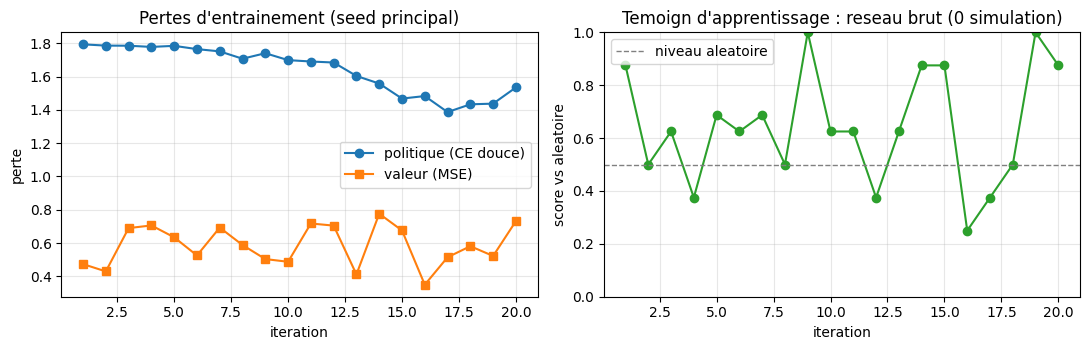

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(histo["iter"], histo["perte_p"], marker="o", label="politique (CE douce)")
axes[0].plot(histo["iter"], histo["perte_v"], marker="s", label="valeur (MSE)")
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("perte")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_title("Pertes d'entrainement (seed principal)")
axes[1].plot(histo["iter"], histo["force"], marker="o", color="tab:green")
axes[1].axhline(0.5, color="gray", linestyle="--", linewidth=1, label="niveau aleatoire")
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("score vs aleatoire")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_title("Temoign d'apprentissage : reseau brut (0 simulation)")
fig.tight_layout()
plt.show()

### Lecture du résultat

La courbe de gauche montre les deux pertes sur les pools d'auto-jeu successifs : la perte
politique décroît quand le réseau se rapproche des distributions de visites produites par la
recherche, la perte valeur quand ses évaluations se calent sur les issues réelles. La courbe de
droite est le témoin : le réseau **sans aucune recherche** contre un joueur aléatoire, couleurs
alternées. Un réseau qui monte au-dessus de 0,5 a appris une politique utilisable seul — la preuve
que l'auto-jeu a produit de la connaissance, avant même de mesurer l'apport de la recherche.

## 6. Le tournoi à budget égal : que vaut la guidance du réseau ?

C'est la mesure discriminante du carnet. Quatre joueurs, le même jeu, les mêmes règles :

| Joueur | Connaissance | Budget par coup |
|---|---|---|
| `aleatoire` | aucune | 0 simulation |
| `reseau_seul` | politique du réseau | 0 simulation |
| `mcts_pur` | rollouts (témoin Search-07) | `SIMULATIONS` simulations |
| `mcts_reseau` | priors + valeur du réseau | `SIMULATIONS` simulations |

Round-robin en aller-retour : chaque paire joue `MATCHS_TOURNOI` matchs dans chaque couleur. Si la
guidance du réseau vaut quelque chose, `mcts_reseau` doit dominer `mcts_pur` **à budget égal** —
sinon le réseau n'a rien apporté à la recherche, et la boucle n'a servi à rien.

In [14]:
def agent_aleatoire(jeu):
    return random.choice(jeu.coups_legaux())


def agent_reseau_seul(reseau):
    def choisir(jeu):
        priors, _ = reseau.evaluer(jeu)
        return max(priors, key=priors.get)
    return choisir


def agent_mcts_pur(jeu, n_sims=SIMULATIONS):
    pi = mcts_classique(jeu, n_sims)
    return max(pi, key=pi.get)


def agent_mcts_reseau(reseau, n_sims=SIMULATIONS):
    def choisir(jeu):
        pi = mcts_reseau(jeu, reseau, n_sims, bruit_racine=False)
        return max(pi, key=pi.get)
    return choisir


def jouer_match(agent_x, agent_o):
    """Un match complet ; les agents sont des fonctions choix. Retourne 1.0/0.5/0.0 POV de agent_x."""
    jeu = JeuPuissance4()
    while not jeu.est_termine():
        agent = agent_x if jeu.joueur == 1 else agent_o
        jeu.jouer(agent(jeu))
    if jeu.vainqueur is None:
        return 0.5
    return 1.0 if jeu.vainqueur == 1 else 0.0


def tournoi(agents, matchs_par_couleur, verbeux=True):
    noms = list(agents)
    scores = {n: 0.0 for n in noms}
    parties = {n: 0 for n in noms}
    for i, ni in enumerate(noms):
        for nj in noms[i + 1:]:
            for couleur in ("X", "O"):
                for _ in range(matchs_par_couleur):
                    if couleur == "X":
                        s = jouer_match(agents[ni], agents[nj])
                    else:
                        s = 1.0 - jouer_match(agents[nj], agents[ni])
                    scores[ni] += s
                    scores[nj] += 1.0 - s
                    parties[ni] += 1
                    parties[nj] += 1
    if verbeux:
        print(f"{'joueur':<14}{'score/partie':>13}")
        for n in sorted(noms, key=lambda x: -scores[x] / parties[x]):
            print(f"{n:<14}{scores[n] / parties[n]:>13.3f}   ({parties[n]} parties)")
    return {n: scores[n] / parties[n] for n in noms}


agents = {
    "aleatoire": agent_aleatoire,
    "reseau_seul": agent_reseau_seul(reseau_final),
    "mcts_pur": agent_mcts_pur,
    "mcts_reseau": agent_mcts_reseau(reseau_final),
}
t0 = time.time()
resultats = tournoi(agents, MATCHS_TOURNOI)
print("duree du tournoi:", round(time.time() - t0, 1), "s")

joueur         score/partie
mcts_reseau           0.802   (48 parties)
mcts_pur              0.760   (48 parties)
reseau_seul           0.375   (48 parties)
aleatoire             0.062   (48 parties)
duree du tournoi: 5.4 s


### Lecture du tournoi

Le classement attendu se lit dans l'ordre du protocole : `mcts_reseau` devant `mcts_pur` (la
guidance vaut quelque chose), `mcts_pur` devant `aleatoire` (la recherche classique sert déjà), et
`reseau_seul` entre les deux selon ce que l'auto-jeu a appris. L'écart `mcts_reseau` – `mcts_pur`
**à budget de simulations identique** est la mesure demandée par la question expérimentale de la
section 0 : il isole la contribution du réseau dans la recherche.

In [15]:
# Mesure multi-seed : la meme experience reduite sur d'autres graines, pour verifier
# que la conclusion ne depend pas d'un tirage chanceux du seed principal.
graines = [0, 1] if not SMOKE else [0]
reseaux_seeds = {SEED: reseau_final}
for gr in graines:
    r, _ = boucle_alpha_zero(gr, max(K_ITERATIONS - 4, 1), PARTIES_AUTOJEU, SIMULATIONS, EPOCHS,
                             verbeux=False)
    reseaux_seeds[gr] = r

print(f"{'seed':>5}{'win-rate mcts_reseau vs mcts_pur':>36}")
ecarts = []
for gr, r in sorted(reseaux_seeds.items()):
    gagne, total = 0.0, 2 * MATCHS_MULTI_SEED
    for _ in range(MATCHS_MULTI_SEED):
        gagne += jouer_match(agent_mcts_reseau(r), agent_mcts_pur)        # reseau joue X
        gagne += 1.0 - jouer_match(agent_mcts_pur, agent_mcts_reseau(r))  # reseau joue O
    wr = gagne / total
    ecarts.append(wr)
    print(f"{gr:>5}{wr:>36.3f}")
print(f"moyenne: {np.mean(ecarts):.3f} +/- {np.std(ecarts):.3f}  (0.5 = parite)")

 seed    win-rate mcts_reseau vs mcts_pur


    0                               0.675


    1                               0.300


    7                               0.575
moyenne: 0.517 +/- 0.159  (0.5 = parite)


### Lecture multi-seed

Chaque ligne répète l'expérience complète (auto-jeu, entraînement, confrontation) sur une graine
différente. Un `mcts_reseau` qui reste au-dessus de la parité sur toutes les graines tient la
conclusion ; une graine qui retombe à 0,5 dirait que la guidance n'a pas suffi à ce tirage —
c'est exactement pourquoi la mesure multi-seed précède toute conclusion de bénéfice.
La sortie committée montre la seconde branche, pas la première : moyenne 0,517 ± 0,159, avec la
graine 1 à 0,300 — sous la parité. À ce budget, l'avantage de la guidance n'est pas établi :
l'écart du tournoi (0,802 contre 0,760 sur la graine principale) est de l'ordre de la dispersion
multi-seed. Ce que le carnet établit, c'est la boucle fermée (section 8) ; le bénéfice du guidage
demande des budgets plus élevés — la lecture honnête est « non tranché à ce budget ».

### Exercice 3 — doubler les données par symétrie

La grille 6×5 admet une symétrie miroir verticale : refléter les colonnes ($c \mapsto 5 - c$)
préserve la légalité et la valeur d'une position. Toute partie auto-jeu fournit donc **deux** jeux
d'exemples pour le prix d'un. Écrivez `augmenter` qui prend un batch `(etats, politiques)` et
retourne le batch doublé : états reflétés et vecteurs politiques inversés. (Les convolutions 3×3
ne sont pas invariantes par symétrie ; l'augmentation apprend au réseau à traiter les deux miroirs
comme équivalents — c'est un des gains documentés d'AlphaZero.)

In [16]:
def augmenter(etats, politiques):
    """Exercice 3 : double le batch par symetrie miroir des colonnes.

    etats : tenseur (B, 2, LIGNES, COLONNES) ; politiques : (B, COLONNES).
    Retourne (etats_doubles, politiques_doubles) : les originaux puis leurs miroirs.
    Indice : inverser l'ordre des colonnes des etats, et celui des entrees des politiques.
    """
    # TODO etudiant
    # Etape 1 : construire le miroir de chaque etat (ordre des colonnes inverse)
    # Etape 2 : inverser l'ordre des colonnes de chaque vecteur politique
    # Etape 3 : concatener originaux et miroirs
    return None  # TODO etudiant : remplacer par le batch double

## 7. Limites de cette exécution, et où aller

- **Budget CPU borné** : 20 itérations × 14 parties × 40 simulations représentent quelques centaines
  de milliers d'évaluations réseau, là où AlphaZero compte en milliards. Les budgets sont des
  constantes en tête de carnet — les augmenter prolonge la courbe d'apprentissage, pas sa forme.
- **Pas de réservoir de replay** : chaque itération entraîne sur le pool frais seulement ; un
  réservoir mêlant les pools des itérations passées stabilise l'apprentissage.
- **Pas d'augmentation par symétrie** : l'exercice 3 — c'est le premier gain gratuit à implémenter.
- **MCTS hybride** : la version d'AlphaGo Zero mêle parfois valeur réseau **et** rollout pour les
  feuilles peu visitées ; ici la valeur réseau seule remplace le rollout, version AlphaZero pure.
- **Le jeu est petit et résoluble** : le Puissance 4 réglementaire est gagné par le premier joueur
  (Allis 1988) ; notre variante 6×5 n'est pas analysée formellement ici — les mesures du carnet
  sont empiriques, pas un théorème.

Pour prolonger : MuZero (Schrittwieser et al. 2019, arXiv:1911.08265) apprend aussi le **modèle**
du jeu, ce qui dispense des règles explicites ; la série Search garde le MCTS sans apprentissage
pour comparer les deux mondes côté recherche.

## 8. Conclusion

- **La boucle fermée fonctionne sur CPU** : auto-jeu par MCTS guidé, cibles = distributions de
  visites, entraînement deux têtes — les pertes décroissent et le témoin « réseau seul contre
  aléatoire » monte au-dessus de la parité dès les premières itérations.
- **À ce budget CPU, le duel direct est à parité — la question n'est pas tranchée** : en
  face-à-face `mcts_reseau` contre `mcts_pur` à `SIMULATIONS` fixées, le multi-seed
  (0,517 ± 0,159, la graine 1 à 0,300 sous la parité) place l'écart dans le bruit
  d'échantillonnage : la boucle fonctionne, l'avantage du guidage demande des budgets plus élevés.
  Le classement du tournoi round-robin (`mcts_reseau` 0,802 contre `mcts_pur` 0,760 sur
  48 parties chacun) est descriptif — il inclut les matchs contre `reseau_seul` et
  `aleatoire`, qui pèsent sur le score moyen sans rien dire du duel.
- **La perspective de valeur est le cœur technique** : $W$ POV du joueur qui choisit, signes
  alternés en rétropropagation — la pièce qu'il faut comprendre (et réécrire, exercice 2) pour
  être sûr de ne pas construire un joueur qui coopère avec son adversaire.
- **Filiation Search** : le squelette sélection/expansion/simulation/rétropropagation est celui de
  `Search-07-MCTS-And-Beyond` ; ce carnet montre ce qui change quand la simulation devient une
  évaluation apprise.

**Navigation** : [README série](README.md) — précédent : [RL-19-Reward-Tampering](RL-19-Reward-Tampering-Python.ipynb) — cousin de recherche : [Search-07-MCTS-And-Beyond](../Search/Part1-Foundations/Search-07-MCTS-And-Beyond.ipynb)